# Libraries importation

In [2]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import seaborn as sns
from scipy.stats import norm
from scipy.stats import chi2

# Data colection

## Sélection des actifs

In [60]:
print ("================= Welcome to the Portfolio Risk Engine!=====================")
print ()
print ("Please enter the tickers of your portfolio assets (separated by commas):")
tickers = []
for i in range(6):
    ticker = input(f'Enter the {i+1} asset ticker: ')
    tickers.append(ticker)

print (f"You have entered the following tickers: {tickers}")

================= Welcome to the Portfolio Risk Engine!=====================

Please enter the tickers of your portfolio assets (separated by commas):
You have entered the following tickers: ['aapl', 'nee', 'pg', 'jpm', 'amzn', 'cat']


In [3]:
#tickers = [actif1, actif2, actif3, actif4, actif5, actif6]
test = yf.download(tickers, start="2017-01-01", end="2023-01-01")['Close']
test = test.dropna(axis=1, how='all')  # Drop columns with all NaN values
print (test)

NameError: name 'tickers' is not defined

In [36]:
tickers = ('AAPL', 'JPM','JNJ','AMZN','PG','NEE','CAT','AMT','GLD')
data = yf.download (tickers, start='2017-01-01', end='2023-01-01')['Close']
data = pd.DataFrame(data).dropna()
data

[*********************100%***********************]  9 of 9 completed


Ticker,AAPL,AMT,AMZN,CAT,GLD,JNJ,JPM,NEE,PG
Date,,,,,,,,,
2017-01-03,26.698212,82.250206,37.683498,76.141861,110.470001,88.870560,67.225044,23.160507,64.618896
2017-01-04,26.668325,82.397446,37.859001,75.801636,110.860001,88.724792,67.349068,23.228781,64.849113
2017-01-05,26.803951,82.110748,39.022499,75.339851,112.580002,89.653061,66.729111,23.215128,65.278877
2017-01-06,27.102764,81.568375,39.799500,75.372276,111.750000,89.223465,66.736870,23.146849,65.255859
2017-01-09,27.351017,81.374641,39.846001,74.829514,112.669998,89.208130,66.783371,23.088322,64.772346
...,...,...,...,...,...,...,...,...,...
2022-12-23,129.547668,184.901520,85.250000,226.521545,167.259995,159.443222,119.621956,75.489128,138.407166
2022-12-27,127.749786,184.910263,83.040001,229.609573,168.669998,159.398300,120.041115,75.336662,139.613312
2022-12-28,123.829742,184.208908,81.820000,226.058777,167.910004,158.706604,120.697189,74.583290,137.808655


# Poids des actifs

In [ ]:
weights = []
for ticker in tickers : 
    weight = float(input(f'Enter the weight of {ticker}: '))
    weights.append(weight)
    print (f"You have entered the following weight for {ticker}: {weight}")
    print (f"Current weights: {weights}")

if sum(weights) != 1:
    print("Error: The sum of the weights must be equal to 1.")

You have entered the following weight for aapl: 0.2
Current weights: [0.2]
You have entered the following weight for nee: 0.1
Current weights: [0.2, 0.1]
You have entered the following weight for pg: 0.1
Current weights: [0.2, 0.1, 0.1]
You have entered the following weight for jpm: 0.3
Current weights: [0.2, 0.1, 0.1, 0.3]
You have entered the following weight for amzn: 0.15
Current weights: [0.2, 0.1, 0.1, 0.3, 0.15]
You have entered the following weight for cat: 0.15
Current weights: [0.2, 0.1, 0.1, 0.3, 0.15, 0.15]


# Analytics & models

## Calcul du rendement du portefeuille

In [92]:
daily_returns = data.pct_change().dropna() #rendements journaliers
assets_returns = daily_returns.mean (axis=0) #moyennes des rendements par actifs
print (assets_returns)


Ticker
AAPL    0.001233
AMT     0.000684
AMZN    0.000758
CAT     0.000921
GLD     0.000322
JNJ     0.000461
JPM     0.000574
NEE     0.000904
PG      0.000583
dtype: float64


In [38]:
portfolio_weights = np.array([0.15, 0.1, 0.2, 0.1, 0.2, 0.1, 0.05, 0.05, 0.05])  # Example weights for the assets
portfolio = pd.DataFrame ({'Assets': daily_returns.columns, 'Returns': assets_returns, 'Weights': portfolio_weights})

In [40]:
portfolio_return = portfolio['Returns']*portfolio['Weights']
print (portfolio)
print(f"Expected Portfolio Return: {portfolio_return.sum() * 100:.4f}%")

       Assets   Returns  Weights
Ticker                          
AAPL     AAPL  0.001233     0.15
AMT       AMT  0.000684     0.10
AMZN     AMZN  0.000758     0.20
CAT       CAT  0.000921     0.10
GLD       GLD  0.000322     0.20
JNJ       JNJ  0.000461     0.10
JPM       JPM  0.000574     0.05
NEE       NEE  0.000904     0.05
PG         PG  0.000583     0.05
Expected Portfolio Return: 0.0710%


## Correlation heatmap

<Axes: xlabel='Ticker', ylabel='Ticker'>

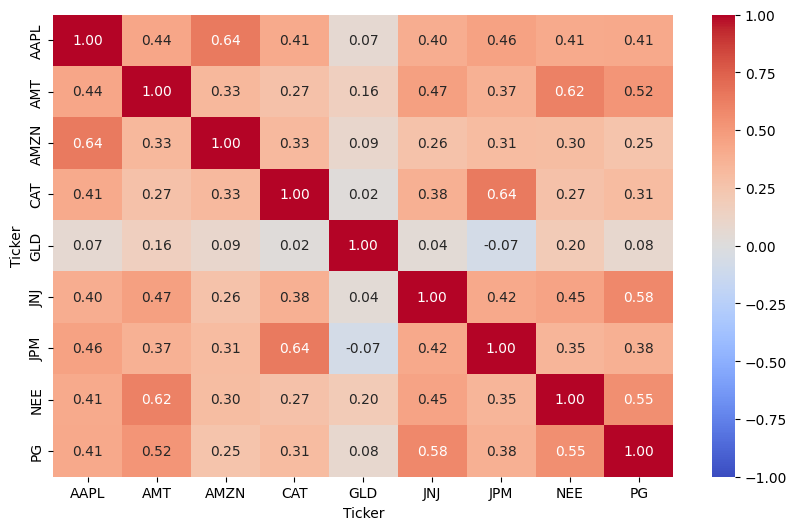

In [41]:
plt.figure(figsize=(10, 6))
sns.heatmap(daily_returns.corr(), vmin=-1, vmax=1, annot=True, cmap='coolwarm', fmt=".2f")

## Historical VaR

In [93]:
pnl = daily_returns @ portfolio_weights
#print (pnl)
sorted_pnl = pnl.sort_values(ascending=True)
print (sorted_pnl)


Date
2020-03-16   -0.073554
2020-03-12   -0.073525
2020-03-09   -0.057206
2022-04-29   -0.044736
2020-06-11   -0.040593
                ...   
2020-03-26    0.052569
2020-03-17    0.062899
2022-11-10    0.064881
2020-03-13    0.067635
2020-03-24    0.068124
Length: 1509, dtype: float64


In [43]:
k_95 = len(sorted_pnl) * (0.05) # 5% quantile
k_99 = len(sorted_pnl) * (0.01) # 1% quantile
hist_var_95 = sorted_pnl.iloc [int(k_95)] # hist_var_95 = np.percentile(sorted_pnl, 5)
hist_var_99 = sorted_pnl.iloc [int(k_99)] # hist_var_99 = np.percentile(sorted_pnl, 1)


hist_cvar_95 = sorted_pnl [sorted_pnl <= hist_var_95].mean()  # Calculate CVaR as the mean of losses beyond VaR
hist_cvar_99 = sorted_pnl [sorted_pnl <= hist_var_99].mean()  # Calculate CVaR as the mean of losses beyond VaR

print (f'According to the historical method, the portfolio is expected to lose at least {- hist_var_95 * 100:.4f}% or more of its value in 5% of the worst cases and on average {-hist_cvar_95 * 100:.4f}% of its value in those cases.\n')
print (f'According to the historical method, the portfolio is expected to lose at least {- hist_var_99 * 100:.4f}% or more of its value in 1% of the worst cases and on average {-hist_cvar_99 * 100:.4f}% of its value in those cases.')

According to the historical method, the portfolio is expected to lose at least 1.6472% or more of its value in 5% of the worst cases and on average 2.5549% of its value in those cases.

According to the historical method, the portfolio is expected to lose at least 2.9179% or more of its value in 1% of the worst cases and on average 4.1935% of its value in those cases.


## Parametric VaR

In [44]:
portfolio_std_dev = np.sqrt(np.dot(portfolio_weights.T, np.dot(daily_returns.cov(), portfolio_weights))) #écart type/volatilité du portefeuille

p_95 = 0.95
p_99 = 0.99

param_var_95 = portfolio_return.sum() - (norm.ppf(p_95) * portfolio_std_dev)
param_var_99 = portfolio_return.sum() - (norm.ppf(p_99) * portfolio_std_dev)

print (f'According to the parametric method, the portfolio is expected to lose at least {-param_var_95 * 100:.4f}% or more of its value in 5% of the worst cases.\n')
print (f'According to the parametric method, the portfolio is expected to lose at least {-param_var_99 * 100:.4f}% or more of its value in 1% of the worst cases.\n')

According to the parametric method, the portfolio is expected to lose at least 1.6979% or more of its value in 5% of the worst cases.

According to the parametric method, the portfolio is expected to lose at least 2.4308% or more of its value in 1% of the worst cases.



# Simulation Monte Carlo

## Simulations des trajectoires

In [45]:
def simulation_gbm (weights, returns, cov, S0 = 1.0, n_days = 252, n_sim = 10000) : 
    np.random.seed (42)
    dt = 1
    
    returns = np.asarray (returns)
    port_values = np.zeros ((n_sim, n_days+1))
    port_values [:,0] = S0

    
    z = np.random.multivariate_normal (np.zeros(len(returns)), cov * dt, size=(n_sim, n_days))  #Composant aléatoire pour la simulation
            
    for t in range  (1, n_days + 1) : 
        asset_returns = (returns - 0.5 * np.diag(cov)) * dt + z [:, t-1]
        port_return = asset_returns @ weights
        port_values [:,t] = port_values [:, t-1] * np.exp (port_return)

    return port_values

In [46]:
simulated_portfolio_values = simulation_gbm (portfolio_weights, assets_returns, daily_returns.cov(), n_days = 15) #n_days = 15 pour calculer la VaR sur 15 jours
print (simulated_portfolio_values)

[[1.         0.99253765 0.98891561 ... 1.003521   1.01827063 1.02902987]
 [1.         0.98508181 0.98448888 ... 0.95361583 0.93343014 0.93058246]
 [1.         0.98438706 0.98944276 ... 0.96289363 0.94465807 0.96440678]
 ...
 [1.         1.01480468 1.01610609 ... 1.10291037 1.09805234 1.09650841]
 [1.         1.00299832 1.00137745 ... 1.02154338 1.03004537 1.02473024]
 [1.         1.02267391 1.01659277 ... 1.02722847 1.01149728 1.0122255 ]]


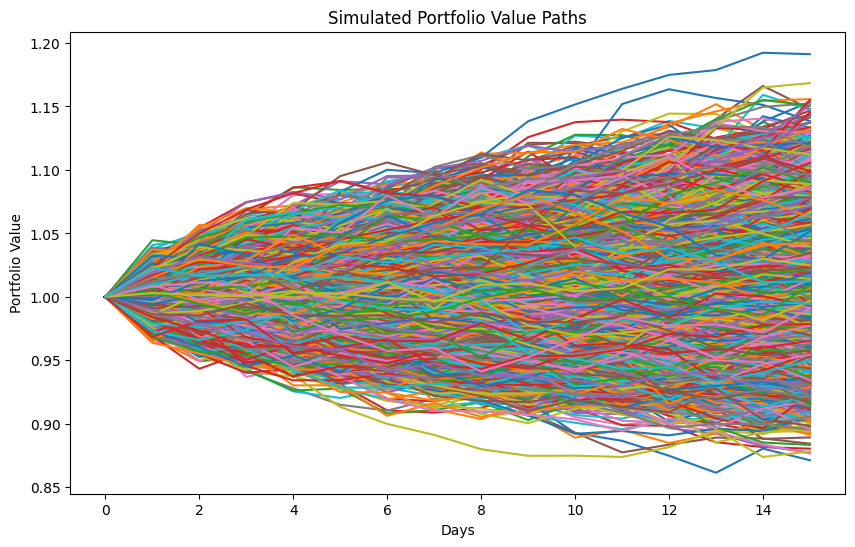

In [47]:
plt.figure(figsize=(10, 6))
t = np.linspace (0, 15, 16)

for i in range(simulated_portfolio_values.shape[0]):
    plt.plot(t, simulated_portfolio_values[i])
plt.title('Simulated Portfolio Value Paths')
plt.xlabel('Days')
plt.ylabel('Portfolio Value')
plt.show()

## Calcul VaR et CVaR

In [49]:
loss = simulated_portfolio_values[:,-1] - simulated_portfolio_values[:,0]
mc_var_95 = np.percentile(loss, 5)
mc_var_99 = np.percentile(loss, 1)
mc_cvar_95 = np.mean(loss[loss <= mc_var_95])
mc_cvar_99 = np.mean(loss[loss <= mc_var_99])

print (f'According to the Monte Carlo simulation, on a 15-day period the portfolio is expected to lose at least {-mc_var_95 * 100:.4f}% or more of its value in 5% of the worst cases and on average {- mc_cvar_95 * 100:.4f}% of its value in those cases.\n')
print (f'According to the Monte Carlo simulation, on a 15-day period the portfolio is expected to lose at least {-mc_var_99 * 100:.4f}% or more of its value in 1% of the worst cases and on average {- mc_cvar_99 * 100:.4f}% of its value in those cases.')

According to the Monte Carlo simulation, on a 15-day period the portfolio is expected to lose at least 5.9847% or more of its value in 5% of the worst cases and on average 7.4504% of its value in those cases.

According to the Monte Carlo simulation, on a 15-day period the portfolio is expected to lose at least 8.3625% or more of its value in 1% of the worst cases and on average 9.4640% of its value in those cases.


# Backtesting

## Test de Kupiec

In [50]:
n = len (pnl)
x = pnl [pnl < param_var_95].count ()  #nb of days where daily return is less than than the parametric_VaR
alpha = 1 - p_95 #probabilité d'échecs théorique
p = x/n  #probabilité d'échecs observée

ll0 = x * np.log (alpha) + (n-x) * np.log (1 - alpha)
ll1 = x * np.log (p) + (n-x) * np.log (1-p)

LR = -2 * (ll0 - ll1) #Likelihood ratio

print (f'===============  Niveau de confiance : {p_95}%  ===============')
print (f'Probabilité d\'échecs observée : {p:.4f}\n'
       f'Ratio de vraisemblance : {LR:.4f}')

if LR <= chi2.ppf (0.95, df = 1) :  #correspond à la loi de distribution de chi2 pour un seui à 95%
    print ('Modèle de VaR non rejeté')
else : 
    print ('Ecart trop grand, modèle de VaR rejeté')

===============  Niveau de confiance : 0.95%  ===============
Probabilité d'échecs observée : 0.0490
Ratio de vraisemblance : 0.0295
Modèle de VaR non rejeté


In [51]:
n = len (pnl)
x = pnl [pnl < param_var_99].count ()  #nb of days where daily return is less than than the parametric_VaR
alpha = 1 - p_99 #probabilité d'échecs théorique
p = x/n  #probabilité d'échecs observée

ll0 = x * np.log (alpha) + (n-x) * np.log (1 - alpha)
ll1 = x * np.log (p) + (n-x) * np.log (1-p)

LR = -2 * (ll0 - ll1) #Likelihood ratio
print (f'===============  Niveau de confiance : {p_99}%  ===============')
print (f'Probabilité d\'échecs observée : {p:.4f}\n'
       f'Ratio de vraisemblance : {LR:.4f}')


if LR <= chi2.ppf (0.99, df = 1) :  #correspond à la loi de distribution de chi2 pour un seui à 95%
    print ('Modèle de VaR non rejeté')
else : 
    print ('Ecart trop grand, modèle de VaR rejeté')

===============  Niveau de confiance : 0.99%  ===============
Probabilité d'échecs observée : 0.0166
Ratio de vraisemblance : 5.4881
Modèle de VaR non rejeté


## Rolling backtesting

In [187]:
#Dans cette étape, on va calculer la VaR quotidienne en ajustant nos données à chaque fois sur les 250 derniers jours (soit 1 an)

w = 250 #longueur de la fenêtre, le nombre de jours ouvrés (trading days) sur 1 an
n = len (daily_returns)
window = pd.DataFrame(index=daily_returns.index, columns=['Daily Returns', 'VaR'], dtype=float)
window ['Daily Returns'] = pnl
for i in range (w, n) :
    window_ret = daily_returns.iloc [i-w:i]
    window_port_ret = window_ret.mean (axis= 0) * portfolio_weights
    window_port_std = np.sqrt (portfolio_weights.T @ window_ret.cov() @ portfolio_weights)
    window_var = window_port_ret.sum() - (norm.ppf(p_95) * window_port_std)
    window.iloc [i, 1] = window_var
print (window)

            Daily Returns       VaR
Date                               
2017-01-04       0.001456       NaN
2017-01-05       0.009943       NaN
2017-01-06       0.002924       NaN
2017-01-09       0.001817       NaN
2017-01-10       0.000480       NaN
...                   ...       ...
2022-12-23       0.006655 -0.023023
2022-12-27      -0.003731 -0.023014
2022-12-28      -0.011675 -0.023031
2022-12-29       0.015721 -0.023109
2022-12-30      -0.001992 -0.023107

[1509 rows x 2 columns]


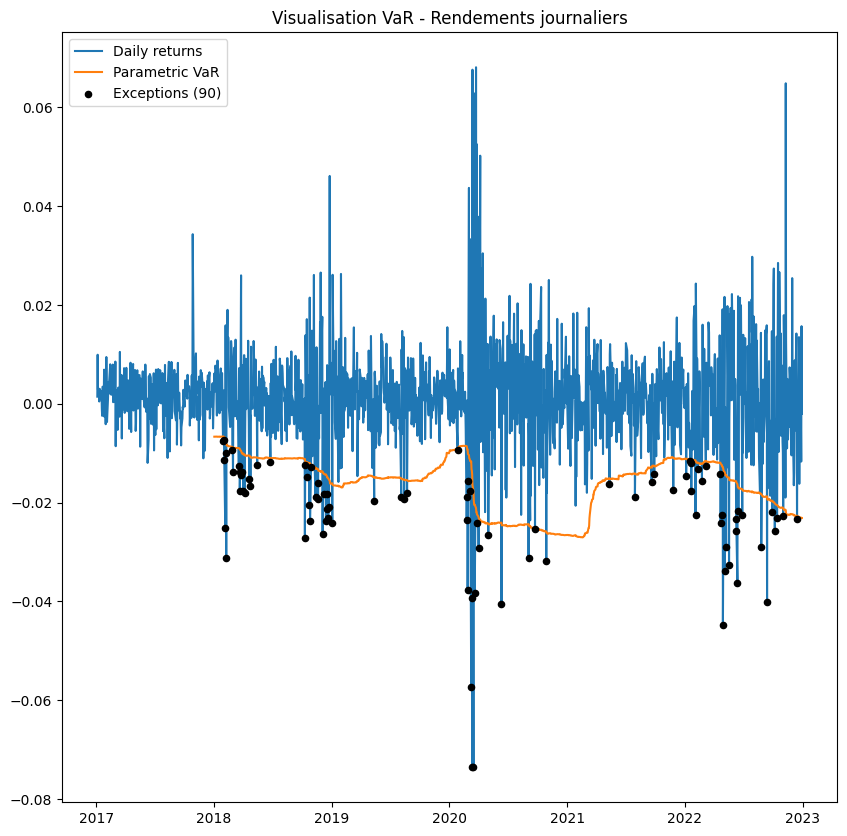

In [192]:
exceptions = window[window['Daily Returns'] < window['VaR']]

plt.figure (figsize= (10,10))
plt.plot (window.index, window ['Daily Returns'], label = 'Daily returns')
plt.plot (window.index, window ['VaR'], label = 'Parametric VaR')
plt.scatter(exceptions.index, exceptions['Daily Returns'],
            color='black', s=20, zorder=3, label=f'Exceptions ({len(exceptions)})')
plt.legend ()
plt.title ('Visualisation VaR - Rendements journaliers')
plt.show()